# CIS*4020 — Assignment 3
## Missing-Data Mechanisms (MCAR / MAR / MNAR) and Imputation Strategies
**Luc Levesque**

## 1. Overview

This tutorial covers why data goes missing and how that changes the way you should handle it. In lecture we got a list of strategies for missing values (drop the row, fill with a constant, fill with the mean, fill with a group mean, or model it with kNN or regression), and each one came with a caution like "biases if not random" or "shrinks variance". Here we look at where those cautions come from. By the end you should be able to name the three missing-data mechanisms (MCAR, MAR and MNAR), tell which strategies give a wrong answer under each one, and compare the strategies yourself in pandas and scikit-learn. You should already know pandas, scikit-learn's fit/transform, mean and standard deviation, linear regression and kNN. MCAR, MAR and MNAR were not covered in lecture, so nothing about them is assumed. The tutorial takes about 25 minutes.

## 2. Motivation

**A survey with gaps**

A professor emails an optional survey to a class of 2,000 students asking for their exam score. About 30% never answer. The professor averages the answers that came back and reports that as the class average.

Whether that number is right depends on why the 30% didn't answer. Here are three stories that all give the same 30% of blanks:

| Story | Who is missing? | Can the average be trusted? |
|---|---|---|
| A. The mail server dropped 30% of the emails at random. | A random sample of the class. | Yes, the students who answered still look like the whole class. |
| B. Students who studied very little ignored the email. | Mostly low-effort students, who also tend to score lower. | No, it is too high. But study hours are recorded for everyone, so there is something to correct it with. |
| C. Students with a bad score didn't want to report it. | Mostly low scorers, whatever their study habits. | No, it is too high, and nothing recorded says by how much. |

All three datasets have the same shape and the same `df.isna().sum()`, but they are three different problems. That is the main idea of this tutorial: the amount of missing data tells you how much information was lost, while the reason it is missing tells you whether your answer is wrong.

**Why this step can't be skipped**

- Real data has gaps. The causes listed in lecture include equipment malfunction, data not entered due to a misunderstanding, and people declining to give information like their age and weight. In Assignment 1, OULAD's `imd_band` had 1,111 missing values recorded as `"?"`.
- Many models can't run with gaps. The kNN lecture listed missing data as something kNN is sensitive to, as a distance can't be computed to a point with a missing value. scikit-learn's kNN raises an error (shown in section 4.7). So something has to be done, and every option has a cost.
- The easiest options are the risky ones. `dropna()` and `fillna(mean)` are one line each and never raise an error, but they can bias the results without any warning. We measure this below.

## 3. The concept

### 3.1 Look at the gaps, not the values

For the column with gaps (the exam score, $Y$), picture an extra column $R$ that only records whether each value is missing:

$$R_i = \begin{cases} 1 & \text{if student } i\text{'s score is missing} \\ 0 & \text{if it was recorded} \end{cases}$$

$R$ is called the missingness indicator. In pandas it is `df["exam_score"].isna()`.

A missingness mechanism answers one question: what does the probability that $R_i = 1$ depend on? There are three possible answers. Below, $X$ stands for the other columns, which are observed for everyone (study hours, prior GPA).

### 3.2 The three mechanisms

**MCAR (Missing Completely At Random):** the chance of being missing depends on nothing in the data.

$$P(R = 1 \mid X, Y) = P(R = 1)$$

In words: knowing a student's study hours ($X$) or even their true score ($Y$) says nothing about whether the score is missing. Every student has the same chance of a blank. This is story A, and "equipment malfunction" from lecture is the usual example.

**MAR (Missing At Random):** the chance of being missing depends only on columns that were observed.

$$P(R = 1 \mid X, Y) = P(R = 1 \mid X)$$

In words: once a student's study hours ($X$) are known, their score ($Y$) gives no extra information about whether it is missing. This is story B. Low-effort students are missing more often, but among students with the same study hours, who is missing is random.

The name is misleading. "Missing At Random" does not mean the gaps are random, and in story B they clearly are not. It means the gaps can be explained by the observed data. The name comes from Rubin (1976).

**MNAR (Missing Not At Random):** the chance of being missing depends on the missing value itself, even after accounting for everything observed.

$$P(R = 1 \mid X, Y) \text{ still depends on } Y$$

This is story C, a low score causes the blank. The lecture example of people declining to give their weight is usually MNAR too, as whether someone declines tends to depend on the weight itself.

| | Missingness depends on | Survey story | Cause from lecture |
|---|---|---|---|
| MCAR | nothing | A: server dropped emails | equipment malfunction |
| MAR | columns that were observed | B: low study hours, no reply | data not entered for a known group |
| MNAR | the missing value itself | C: low score, no reply | people decline to give their weight |

One case from lecture is none of these: an attribute that is not applicable (annual income for a child). There is no true value hidden there, so it should not be imputed. It gets its own category or flag instead.

### 3.3 The strategies from lecture

Imputation means filling in a missing value with an estimate. These are the strategies from lecture, in the order they are tested below:

| Strategy (lecture) | What it does | In code |
|---|---|---|
| Ignore the tuple | Deletes every row with a gap. Also called listwise deletion or complete-case analysis. | `df.dropna()` |
| Global constant | Fills with a fixed value like `"unknown"`. Mostly for categorical columns, where it makes a new category. | `df.fillna("unknown")` |
| Attribute mean / median | Fills every gap with the column's mean (or median). | `SimpleImputer(strategy="mean")` |
| Class- or group-conditional mean | Splits rows into groups and fills each gap with the mean of its own group. | `groupby(...).transform("mean")` |
| Most probable value: kNN | Finds the $k$ most similar complete rows using the other columns and averages their values. | `KNNImputer` |
| Most probable value: regression | Fits a regression that predicts the column from the other columns, and fills each gap with the prediction. | `IterativeImputer` |

One more is added that was not in lecture, as it fixes a problem that shows up later. Stochastic regression imputation fills each gap with the regression prediction plus random noise of the right size.

The first three strategies only look at the column with gaps. The last three use the other columns to decide what to fill in. This difference decides which strategies work under MAR.

## 4. Worked example

### 4.1 Setup
All data is generated inside the notebook, so there is nothing to download. One seed controls all the randomness.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (must come before IterativeImputer)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 4020
rng = np.random.default_rng(SEED)
pd.set_option("display.precision", 2)

### 4.2 A complete dataset where the truth is known

On real data an imputation method can't be checked, as the true values are the ones that are missing. So we do the opposite. We build a complete class of 2,000 students and delete values ourselves, so every method can be compared against the real answer.

Each student has weekly study hours, a prior GPA, and an exam score that depends on both plus noise.

In [2]:
N = 2000
study_hours = rng.gamma(shape=4, scale=2.5, size=N)          # weekly hours, right-skewed, mean about 10
prior_gpa = np.clip(rng.normal(2.9, 0.5, size=N), 0, 4)
exam_score = 30 + 1.8 * study_hours + 7 * prior_gpa + rng.normal(0, 8, size=N)
exam_score = np.clip(exam_score, 0, 100)

full = pd.DataFrame({"study_hours": study_hours,
                     "prior_gpa": prior_gpa,
                     "exam_score": exam_score})
COLS = list(full.columns)
full.describe()

,study_hours,prior_gpa,exam_score
count,2000.00,2000.00,2000.00
mean,9.91,2.90,68.07
std,5.08,0.49,12.10
min,0.98,1.01,29.11
25%,6.26,2.56,59.81
50%,9.14,2.91,67.14
75%,12.73,3.24,76.19
max,38.38,4.00,100.00


The true class mean is about 68 with a standard deviation of about 12. Every method below is trying to get these numbers back.

### 4.3 Deleting scores three ways

About 30% of `exam_score` is removed three times, once per mechanism. The helper turns a "driver" column into a probability of being missing using a logistic curve. A negative `strength` means low values of the driver are more likely to go missing. Only the driver changes between the three versions:

- MCAR: no driver, a coin flip per row (story A).
- MAR: the driver is `study_hours`, a column that is kept (story B).
- MNAR: the driver is `exam_score`, the column being deleted (story C).

In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def missing_mask(driver, strength, rate, rng):
    """Boolean mask (True = missing). P(missing) follows a logistic curve in the standardized driver."""
    z = (driver - driver.mean()) / driver.std()
    lo, hi = -10.0, 10.0
    for _ in range(60):                       # bisection: find the intercept that gives the target rate
        b0 = (lo + hi) / 2
        if sigmoid(b0 + strength * z).mean() < rate:
            lo = b0
        else:
            hi = b0
    return rng.random(len(driver)) < sigmoid(b0 + strength * z)


def make_missing(df, mechanism, rate=0.30, strength=-2.0, rng=rng):
    out = df.copy()
    if mechanism == "MCAR":
        mask = rng.random(len(df)) < rate                             # depends on nothing
    elif mechanism == "MAR":
        mask = missing_mask(df["study_hours"], strength, rate, rng)   # depends on an OBSERVED column
    elif mechanism == "MNAR":
        mask = missing_mask(df["exam_score"], strength, rate, rng)    # depends on the value ITSELF
    else:
        raise ValueError(mechanism)
    out.loc[mask, "exam_score"] = np.nan
    return out


MECHS = ["MCAR", "MAR", "MNAR"]
datasets = {m: make_missing(full, m) for m in MECHS}
pd.Series({m: d["exam_score"].isna().mean() for m, d in datasets.items()}, name="fraction missing")

MCAR    0.30
MAR     0.32
MNAR    0.29
Name: fraction missing, dtype: float64

All three datasets are missing about 30% of the scores. If the amount missing was all that mattered, they would be interchangeable. This is what the MAR version looks like to an analyst:

In [4]:
datasets["MAR"].head(8)

,study_hours,prior_gpa,exam_score
0,13.40,2.85,66.06
1,8.37,2.88,61.50
2,5.94,3.65,NaN
3,15.97,2.71,75.33
4,13.83,2.58,54.29
5,5.62,3.10,66.81
6,15.35,2.91,81.00
7,5.33,2.73,47.56


### 4.4 What was lost?

Since we built the data, we can look at the true scores of the rows that were deleted.

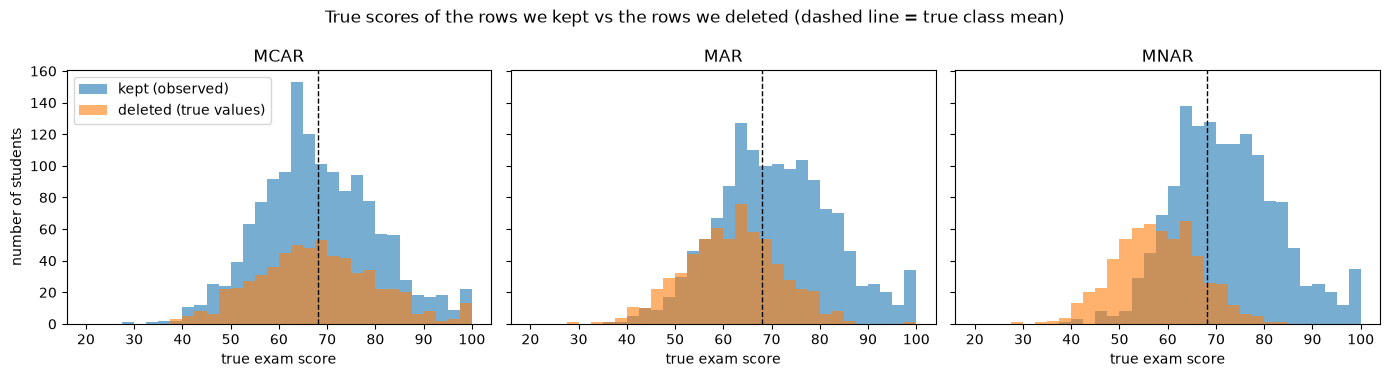

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
bins = np.linspace(20, 100, 33)
for ax, m in zip(axes, MECHS):
    is_missing = datasets[m]["exam_score"].isna()
    ax.hist(full.loc[~is_missing, "exam_score"], bins=bins, alpha=0.6, label="kept (observed)")
    ax.hist(full.loc[is_missing, "exam_score"], bins=bins, alpha=0.6, label="deleted (true values)")
    ax.axvline(full["exam_score"].mean(), color="black", linestyle="--", linewidth=1)
    ax.set_title(m)
    ax.set_xlabel("true exam score")
axes[0].set_ylabel("number of students")
axes[0].legend()
fig.suptitle("True scores of the rows we kept vs the rows we deleted (dashed line = true class mean)")
plt.tight_layout()
plt.show()

- MCAR: the deleted students (orange) have the same shape as the kept students (blue), just fewer of them. They look like everyone else.
- MAR and MNAR: the deleted students sit to the left, so they are mostly low scorers. The class that is left looks stronger than it really is.
- MNAR is the most extreme, as the score itself decides who is deleted.

Next is the "do nothing" analysis, which averages the scores that are left. This is what `df["exam_score"].mean()` does, since pandas skips `NaN`.

In [6]:
naive = pd.DataFrame({
    "true mean": full["exam_score"].mean(),
    "mean of observed scores": {m: d["exam_score"].mean() for m, d in datasets.items()},
})
naive["bias"] = naive["mean of observed scores"] - naive["true mean"]
naive

,true mean,mean of observed scores,bias
MCAR,68.07,68.17,0.09
MAR,68.07,70.98,2.91
MNAR,68.07,72.20,4.13


Under MCAR the mean is off by about 0.1 points, which is sampling noise. Under MAR it is about 3 points too high and under MNAR about 4 points too high. More students would not fix this, as the error comes from who is missing and not from how many rows there are. This is the lecture's caution for dropping rows, "biases if not random".

### 4.5 Can the data tell us which mechanism we have?

Real datasets don't come labelled as MAR. A common check is to compare the observed columns between the rows that have a score and the rows that don't.

In [7]:
diag = pd.DataFrame({
    m: d.groupby(d["exam_score"].isna())["study_hours"].mean()
    for m, d in datasets.items()
}).T
diag.columns = ["mean study_hours | score observed", "mean study_hours | score missing"]
diag["difference"] = diag.iloc[:, 1] - diag.iloc[:, 0]
diag

,mean study_hours | score observed,mean study_hours | score missing,difference
MCAR,9.88,9.97,0.09
MAR,11.61,6.26,-5.35
MNAR,11.01,7.19,-3.82


- MCAR: both groups study about the same amount (9.9 vs 10.0 hours), so there is no pattern.
- MAR: students with a missing score study about 5 hours less. The gaps are related to an observed column, so this is not MCAR.
- MNAR: students with a missing score also study about 4 hours less. Study hours were not used to delete these scores, but low scorers tend to study less, so the same pattern shows up.

So this check can rule out MCAR, but it cannot separate MAR from MNAR. They look the same in the observed data, as what makes them different is inside the missing values. Choosing between them takes knowledge of how the data was collected (would a student hide a bad score?), not a statistical test.

### 4.6 Comparing the strategies

The strategies from lecture are now run on all three datasets. The group-conditional mean needs groups, so students are binned into four equal-frequency bands of study hours (the same binning idea as the noisy-data slide), and each gap is filled with the mean score of that student's band.

"Fill with a constant" is left out, as it is meant for categorical columns. For a numeric score, any constant is just a worse version of the mean.

In [8]:
def impute(df, method, cols=COLS, seed=SEED):
    """Return a copy of df[cols] with exam_score filled in (or with incomplete rows dropped)."""
    d = df[cols].copy()
    if method == "drop rows":
        return d.dropna()
    if method == "mean":
        d["exam_score"] = d["exam_score"].fillna(d["exam_score"].mean())
        return d
    if method == "group mean":
        band = pd.qcut(df["study_hours"], q=4)                         # 4 equal-frequency study bands
        d["exam_score"] = d["exam_score"].fillna(d.groupby(band, observed=True)["exam_score"].transform("mean"))
        return d
    if method == "kNN":
        scaler = StandardScaler().fit(d)                               # kNN uses distances, so scale first
        filled = KNNImputer(n_neighbors=10).fit_transform(scaler.transform(d))
        filled = scaler.inverse_transform(filled)
    elif method == "regression":
        filled = IterativeImputer(random_state=seed).fit_transform(d)
    elif method == "stochastic regression":
        filled = IterativeImputer(sample_posterior=True, random_state=seed).fit_transform(d)
    else:
        raise ValueError(method)
    return pd.DataFrame(filled, columns=cols, index=d.index)

A method can look fine on one statistic and fail on another, so each one is scored on three things:

1. Mean exam score: is the class average right?
2. Standard deviation: is the spread of scores right?
3. Slope of score on study hours from a linear regression: is the relationship between columns right?

"Truth" is each of these computed on the complete data.

In [9]:
def summarize(d):
    slope = LinearRegression().fit(d[["study_hours", "prior_gpa"]], d["exam_score"]).coef_[0]
    return {"mean": d["exam_score"].mean(), "std": d["exam_score"].std(), "slope": slope}


METHODS = ["drop rows", "mean", "group mean", "kNN", "regression", "stochastic regression"]
truth = summarize(full)

rows = [{"mechanism": m, "method": meth, **summarize(impute(datasets[m], meth))}
        for m in MECHS for meth in METHODS]
results = pd.DataFrame(rows)


def bias_table(metric):
    """Estimate minus truth for one metric: rows = methods, columns = mechanisms. 0 is perfect."""
    table = results.pivot(index="method", columns="mechanism", values=metric).loc[METHODS, MECHS]
    return (table - truth[metric]).round(2)


print("Truth on the complete data:", {k: round(float(v), 2) for k, v in truth.items()})
for metric, label in [("mean", "MEAN exam score"), ("std", "STANDARD DEVIATION of exam score"),
                      ("slope", "SLOPE of score on study hours")]:
    print(f"\nError in the {label} (estimate - truth)")
    display(bias_table(metric))

Truth on the complete data: {'mean': 68.07, 'std': 12.1, 'slope': 1.67}

Error in the MEAN exam score (estimate - truth)


mechanism,MCAR,MAR,MNAR
method,,,
drop rows,0.09,2.91,4.13
mean,0.09,2.91,4.13
group mean,0.19,0.07,2.70
kNN,0.08,0.03,2.33
regression,0.11,0.05,2.29
stochastic regression,0.20,0.15,2.27



Error in the STANDARD DEVIATION of exam score (estimate - truth)


mechanism,MCAR,MAR,MNAR
method,,,
drop rows,-0.08,-0.13,-1.28
mean,-2.06,-2.22,-2.98
group mean,-1.18,-1.05,-2.33
kNN,-0.86,-0.86,-2.10
regression,-0.84,-0.99,-2.10
stochastic regression,0.02,-0.08,-1.38



Error in the SLOPE of score on study hours (estimate - truth)


mechanism,MCAR,MAR,MNAR
method,,,
drop rows,-0.00,-0.02,-0.23
mean,-0.53,-0.55,-0.59
group mean,-0.11,-0.01,-0.27
kNN,-0.04,-0.01,-0.24
regression,-0.00,-0.02,-0.23
stochastic regression,0.00,-0.03,-0.25


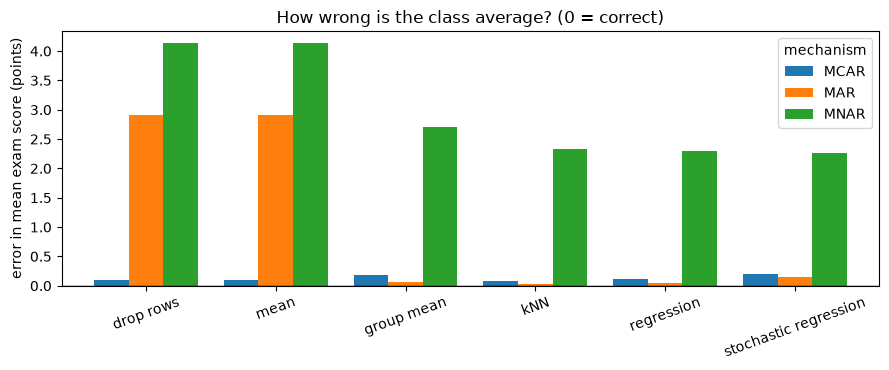

In [10]:
ax = bias_table("mean").plot.bar(figsize=(9, 3.8), rot=20, width=0.8)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("error in mean exam score (points)")
ax.set_xlabel("")
ax.set_title("How wrong is the class average? (0 = correct)")
plt.tight_layout()
plt.show()

The tables are easier to read one mechanism at a time.

**MCAR (first column):** every method gets the mean right, within about 0.2 points. The other two tables are different. Mean imputation shrinks the standard deviation by about 2 points (12.1 to 10.0) and cuts the slope by about a third (1.67 to 1.14). Dropping rows gets all three right. So under MCAR, dropping rows only costs sample size, while mean imputation gives wrong answers.

**MAR (second column):**
- Drop rows and mean are both about 2.9 points too high on the class mean. They always match on the mean, since filling gaps with the observed mean can't move it.
- Group mean, kNN and regression are all within about 0.1 of the true mean. The group mean is enough here because study hours are what drive the missingness.
- The group mean is worse on the other two measures. Everyone in a band gets the same value, so the spread is about 1 point too small, and the slope is slightly flattened in the MCAR column. kNN and regression use each student's actual study hours and GPA, not a band.

Under MAR, the strategies split into the ones that ignore the other columns (drop rows, mean) and the ones that use them. This matches the definition: MAR means the observed columns explain the gaps, so a method only works if it uses those columns.

I didn't expect drop rows to still get the slope right under MAR (off by about 0.02) when its mean is so far off. The missingness depends on study hours, which is a predictor in that regression, and deleting rows based on a predictor doesn't change the line fitted through the rest. So whether dropping rows is acceptable depends on what is being estimated.

**MNAR (third column):** no method works. The best ones are still about 2.3 points too high on the mean, and every method gets the slope wrong. kNN and regression help a little, as study hours and GPA carry some information about the score. But the part of the missingness that depends on the score itself was never recorded, so no method can learn it.

**Why mean imputation changes the spread and the slope**

Below is the same MAR data filled in three ways. Grey points are observed scores and red points are imputed.

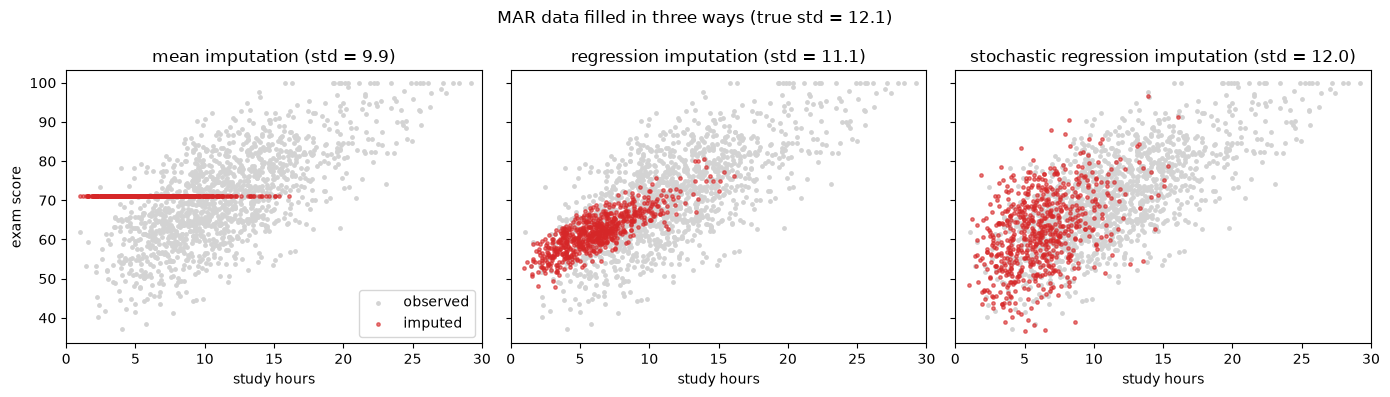

In [11]:
mar = datasets["MAR"]
was_missing = mar["exam_score"].isna()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, meth in zip(axes, ["mean", "regression", "stochastic regression"]):
    filled = impute(mar, meth)
    ax.scatter(filled.loc[~was_missing, "study_hours"], filled.loc[~was_missing, "exam_score"],
               s=6, color="lightgrey", label="observed")
    ax.scatter(filled.loc[was_missing, "study_hours"], filled.loc[was_missing, "exam_score"],
               s=6, color="tab:red", alpha=0.6, label="imputed")
    ax.set_title(f"{meth} imputation (std = {filled['exam_score'].std():.1f})")
    ax.set_xlabel("study hours")
    ax.set_xlim(0, 30)
axes[0].set_ylabel("exam score")
axes[0].legend(loc="lower right")
fig.suptitle(f"MAR data filled in three ways (true std = {truth['std']:.1f})")
plt.tight_layout()
plt.show()

- Mean imputation: every imputed student sits on one horizontal line, so a student who studies 2 hours gets the same score as one who studies 15. That is why the slope drops, and putting 30% of the class on one value is why the spread shrinks. The line also sits above most of the real low-hours students, as the mean came from the stronger students who were left.
- Regression imputation: the red points follow the trend, so the mean and slope are right. But they form a much tighter band than the grey points, since every imputed student is exactly "as predicted". Real students scatter around the line, so the std is still about 1 point too small.
- Stochastic regression: adding random noise to each prediction makes the red points scatter like the grey ones. The std comes back to within about 0.1.

So the lecture's caution "shrinks variance" is not only about the mean. Any method that fills in a best guess makes the data look more predictable than it is. A best guess is the better choice when accurate individual values are needed, and adding noise is the better choice when the distribution matters.

### 4.7 Missing values in the features of a model

So far the gaps were in the column being summarized. In machine learning the gaps are usually in the features. Two points from lecture apply here: kNN is "sensitive to missing data", and model-based imputation has a "risk of leakage".

Below, some students have no recorded `study_hours`, and a kNN classifier predicts whether a student passes (a score of 60 or more).

In [12]:
feat_rng = np.random.default_rng(SEED + 2)
X = full[["study_hours", "prior_gpa"]].copy()
y = (full["exam_score"] >= 60).astype(int)
X.loc[missing_mask(full["prior_gpa"], -1.5, 0.25, feat_rng), "study_hours"] = np.nan   # MAR: driven by GPA

# 1) kNN cannot compute a distance through a NaN, so scikit-learn refuses outright
try:
    KNeighborsClassifier().fit(X, y)
except ValueError as err:
    print("kNN on the raw data ->", str(err).splitlines()[0])

# 2) The safe pattern: put the imputer INSIDE the pipeline
model = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),   # fill gaps + add a 0/1 "was missing" column
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15),
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = cross_val_score(model, X, y, cv=cv)
print(f"Pipeline with imputation -> 5-fold accuracy {scores.mean():.3f} (+/- {scores.std():.3f})")

kNN on the raw data -> Input X contains NaN.
Pipeline with imputation -> 5-fold accuracy 0.756 (+/- 0.012)


- The first line is the error kNN gives when the gaps are left in.
- No leakage: the imputer is a step inside the pipeline, so `cross_val_score` fits it on only the training part of each fold. The median used to fill a test fold never comes from that test fold. Calling `fillna(X["study_hours"].median())` on the whole table first would let the test rows affect the fill value, which is the same kind of leakage avoided in Assignment 2.
- `add_indicator=True` adds a column that flags which values were missing. The missingness here is related to GPA (and so to passing), so the flag is a useful feature. Imputing without it loses that information.

## 5. Common pitfalls & misconceptions

**1. "Missing At Random means the gaps are random."**
This is the most common mistake, and it comes from the name. Random gaps are MCAR. MAR gaps can be very systematic (in the MAR data, students with a missing score studied 5 hours less on average).
- How to avoid: read the names as MCAR = depends on nothing, MAR = depends on things I can see, MNAR = depends on the thing I can't see.

**2. "Only 5% is missing so it doesn't matter" or "40% is missing so the column is useless."**
The percentage says how much information is gone, not whether the result is biased. 30% missing under MCAR gave an error of 0.1 points, while the same 30% under MNAR gave 4 points.
- How to avoid: ask who is missing before asking how many are missing.

**3. "Mean imputation is a safe default."**
It seems safe because it doesn't change the column mean. But it never fixes a biased mean (under MAR it had the same error as dropping rows), and it always shrinks the variance and weakens the relationship with other columns (the slope went from 1.67 to 1.14 even under MCAR). A correlation, regression or kNN that uses the column afterwards is affected too.
- How to avoid: only use mean or median fill for small, roughly random gaps, which is what the lecture table says ("numeric, roughly random gaps").

**4. "I can test which mechanism I have."**
Only partly. Comparing observed columns between missing and non-missing rows can give evidence against MCAR (section 4.5). But MAR and MNAR looked the same there, and no test on the observed data can separate them.
- How to avoid: treat MAR as an assumption that is justified by how the data was collected, and state it in the write-up.

**5. "MAR is a property of the dataset."**
It depends on the dataset and on which columns are used. Data that is MAR given study hours acts like MNAR if the imputation model doesn't include study hours. The exercise below shows this.
- How to avoid: include every column that could explain the missingness in the imputation model, even ones the final analysis doesn't need.

**6. "A better imputer will fix it."**
Under MNAR, kNN and regression imputation were still about 2.3 points off. They can only use relationships found in the observed rows, and under MNAR the observed rows are not representative.
- How to avoid: if MNAR is possible, say so and report how the result changes under different assumptions (ex. if non-responders scored 5 points lower than imputed). Fixing it when the data is collected is better.

**7. Imputing before the train/test split.**
Every imputer learns something from the data (a mean, a set of neighbours, a regression). If it learns from the whole table, test-set information leaks into training.
- How to avoid: put the imputer in a `Pipeline` so it is fit on only the training data (section 4.7).

**8. Treating imputed values as if they were measured.**
After imputation the table looks complete, so it is easy to forget that 30% of a column is estimated. Best-guess imputation makes the data look less variable than it is (section 4.6), so anything that depends on spread, like a confidence interval, comes out too narrow.
- How to avoid: keep a missing flag. The full solution is multiple imputation (impute several times with noise, analyze each copy, combine the results), which is outside the scope of this tutorial.

**9. Imputing values that don't exist.**
"Annual income is not applicable to children" from lecture is not hidden information, as there is no true value. Lecture also notes that when the class label is missing, the row is usually ignored instead of making up a label.
- How to avoid: ask if there is a real value that wasn't recorded. If not, use a separate category or drop the row.

## 6. Your turn

You are given a new version of the exam data. This time, students with a lower prior GPA were less likely to have their score recorded. The cell below creates it.

1. Is this MCAR, MAR or MNAR? Write down your answer and reason before running anything.
2. Estimate the class mean with `"drop rows"`, `"mean"` and `"regression"` imputation. Which is closest to the true mean, `full["exam_score"].mean()`?
3. Run `"regression"` again, but only give the imputer two columns: `["study_hours", "exam_score"]`. (Hint: `impute` has a `cols` argument.) What happens to the error, and why?

This should take about 5 minutes. The solution is two cells down.

In [13]:
ex_rng = np.random.default_rng(SEED + 1)
exercise = full.copy()
exercise.loc[missing_mask(full["prior_gpa"], -2.0, 0.30, ex_rng), "exam_score"] = np.nan
print(f"{exercise['exam_score'].isna().mean():.0%} of exam scores are missing")

# Your code here

29% of exam scores are missing


### Solution (try the exercise first)

In [14]:
true_mean = full["exam_score"].mean()

answers = {meth: impute(exercise, meth)["exam_score"].mean() for meth in ["drop rows", "mean", "regression"]}
answers["regression WITHOUT prior_gpa"] = impute(exercise, "regression",
                                                 cols=["study_hours", "exam_score"])["exam_score"].mean()

solution = pd.Series(answers, name="estimated mean").to_frame()
solution["error"] = solution["estimated mean"] - true_mean
print(f"True mean: {true_mean:.2f}")
solution

True mean: 68.07


,estimated mean,error
drop rows,69.48,1.41
mean,69.48,1.41
regression,68.16,0.08
regression WITHOUT prior_gpa,69.29,1.22


1. MAR: the missingness depends on `prior_gpa`, which is observed for everyone. It is not MCAR as low-GPA students are missing more often, and it is not MNAR as the score itself plays no part among students with the same GPA.
2. Drop rows and mean are both about 1.4 points too high, since low-GPA students score lower and they are the ones missing. Regression imputation is within about 0.1, as it uses each student's GPA to fill in a lower score.
3. Without `prior_gpa`, regression imputation is about 1.2 points too high, almost as bad as doing nothing. The data and the method are the same. But the imputer can no longer see the column that explains the gaps, and `study_hours` is not related to GPA in this data, so it can't replace it. To the imputer, the missingness now depends on something unobserved, which is how MNAR behaves. This is pitfall 5: MAR only helps if the columns that explain the missingness are in the imputation model.

## 7. Key takeaways

- Ask why data is missing before asking how much is missing. The same 30% of gaps gave an error of 0.1 points under MCAR and 4 points under MNAR.
- MCAR depends on nothing, MAR depends on observed columns, and MNAR depends on the missing value itself. The data can give evidence against MCAR, but it can't separate MAR from MNAR.
- Dropping rows and mean imputation are only safe under MCAR, and mean imputation shrinks the variance and weakens relationships even then.
- Under MAR, use the other columns. Group means, kNN and regression imputation remove the bias as long as the columns that explain the missingness are included.
- Imputed values are estimates. Fit imputers on training data only (with a `Pipeline`), keep a missing flag, and state when MNAR is possible, as no imputer fixes it.

## 8. References

1. Antonie, L. (2026). *CIS\*4020 Data Science* [Lecture slides]. University of Guelph. Lectures used: "Data Quality" and "Missing Values" (Sep. 29); "Data Cleaning", "Missing Data" and "How to Handle Missing Data?" (Oct. 1); "K-Nearest Neighbour (KNN)" (Oct. 20).
2. Tan, P.-N., Steinbach, M., Karpatne, A., & Kumar, V. (2019). *Introduction to Data Mining* (2nd ed.). Pearson. (Source of the lecture's "Missing Values" slide.)
3. Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592. https://doi.org/10.1093/biomet/63.3.581 (Origin of the MCAR / MAR / MNAR classification.)
4. van Buuren, S. (2018). *Flexible Imputation of Missing Data* (2nd ed.). CRC Press. https://stefvanbuuren.name/fimd/ (Mean, regression and stochastic regression imputation; why MAR and MNAR can't be told apart.)
5. Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). Wiley.
6. scikit-learn developers. (2026). *Imputation of missing values*. scikit-learn User Guide. https://scikit-learn.org/stable/modules/impute.html (`SimpleImputer`, `KNNImputer`, `IterativeImputer`, `add_indicator`.)

## Generative-AI disclosure

Generative AI was used in this assignment. Claude (Anthropic), through Claude Code, was used to compare topics and to generate the first draft of this notebook: the structure, the code, the figures and a draft of the write-ups. The draft was based on the assignment outline, the lecture slides and my write-ups from Assignments 1 and 2.

**TODO (Luc): finish this truthfully before submitting.** Say what you rewrote, changed and checked yourself.